# Exploratory Data Analysis (EDA)

Este notebook se enfoca en:
1. Configurar las credenciales de Kaggle y descargar el dataset **Amazon Reviews for Sentiment Analysis**.
2. Cargar una muestra representativa del dataset para exploración (debido a su tamaño de ~3.6M de registros).
3. Analizar la distribución de clases (sentimientos positivos vs. negativos).
4. Analizar la longitud de las reseñas (palabras y caracteres).
5. Identificar las palabras y n-gramas más frecuentes.

In [ ]:
import os, sys, subprocess
from getpass import getpass
from urllib.parse import quote

REPO_URL, REPO_DIR = "https://github.com/williamsnunezp/review-nlp-pipeline.git", "/content/review-nlp-pipeline"
token = os.getenv("GITHUB_TOKEN") or getpass("GitHub token (vacío si es público): ").strip()
url = REPO_URL.replace("https://", f"https://{quote(token, safe='')}@") if token else REPO_URL

if os.path.exists(REPO_DIR):
    print("No se clonó el repo: ya existe", REPO_DIR)
else:
    result = subprocess.run(["git", "clone", url, REPO_DIR])
    if result.returncode:
        print("No se clonó el repo.")
    else:
        print(os.listdir(REPO_DIR))
        print("Preparando entorno...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "kagglehub"])
        print("Entorno preparado.")

In [2]:
import os
import sys
import bz2
import kagglehub
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Configuración estricta de rutas para Google Colab
REPO_DIR = '/content/review-nlp-pipeline'
if REPO_DIR not in sys.path:
    sys.path.append(REPO_DIR)

## 1. Descarga del Dataset desde Kaggle
Se crea el directorio temporal de descarga y el directorio de datos crudos. Luego se descarga el dataset **Amazon Reviews** desde Kaggle mediante `kagglehub` y se enlazan los archivos `.bz2` resultantes al directorio de descarga para su posterior procesamiento.

In [3]:
DOWNLOAD_DIR = "/content/review-nlp-pipeline/download"
RAW_DIR = "/content/review-nlp-pipeline/data/raw"
os.makedirs(DOWNLOAD_DIR, exist_ok=True)
os.makedirs(RAW_DIR, exist_ok=True)

# Descargar el dataset usando kagglehub
path = kagglehub.dataset_download("bittlingmayer/amazonreviews")

# Mover los archivos DOWNLOAD_DIR
for file in os.listdir(path):
    src = os.path.join(path, file)
    dst = os.path.join(DOWNLOAD_DIR, file)
    if os.path.exists(dst):
        os.remove(dst)
    os.symlink(src, dst)

print(f"Archivos disponibles en {DOWNLOAD_DIR}:")
print(os.listdir(DOWNLOAD_DIR))

100%|██████████| 493M/493M [00:03<00:00, 156MB/s]  

Extracting files...


Archivos disponibles en /content/review-nlp-pipeline/download:
['train.ft.txt.bz2', 'test.ft.txt.bz2']


## 2. Carga y Parsing de una Muestra de Datos
El dataset original viene en formato fastText comprimido (`.bz2`). En la última celda se procesa y guarda temporalmente como CSV en `data/download/`.

Cargaremos una muestra de 100,000 registros para realizar este EDA eficientemente.

In [4]:
from src.preprocessing import parse_fasttext_line

def load_subset(file_path, max_records):
    labels = []
    texts = []
    count = 0

    with bz2.open(file_path, 'rt', encoding='utf-8') as f:
        for line in f:
            label, text = parse_fasttext_line(line)
            labels.append(label)
            texts.append(text)
            count += 1
            if count >= max_records:
                break

    return pd.DataFrame({'label': labels, 'text': texts})

review_file = f'{DOWNLOAD_DIR}/train.ft.txt.bz2'
if os.path.exists(review_file):
    df = load_subset(review_file, max_records=100000)
    print(f"Muestra de {df.shape[0]} registros cargada correctamente.")
    display(df.head())
else:
    print("Error: Descarga primero el dataset en la celda anterior o verifica la ruta.")

Muestra de 100000 registros cargada correctamente.


,label,text
0,1,Stuning even for the non-gamer: This sound tra...
1,1,The best soundtrack ever to anything.: I'm rea...
2,1,Amazing!: This soundtrack is my favorite music...
3,1,Excellent Soundtrack: I truly like this soundt...
4,1,"Remember, Pull Your Jaw Off The Floor After He..."


## 3. Distribución de Sentimientos
Visualizaremos la proporción de reseñas positivas (`1`) y negativas (`0`).

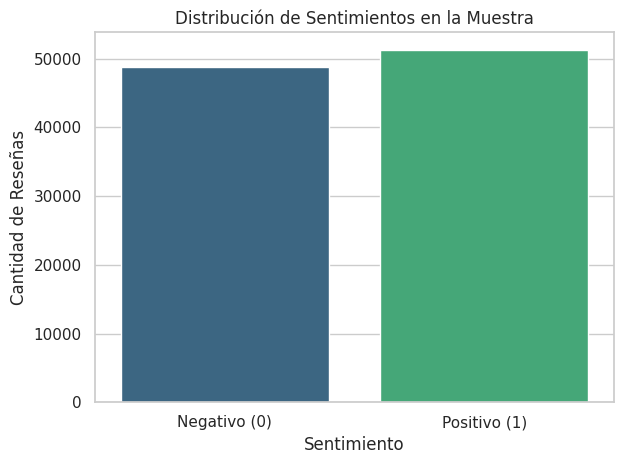

label
1    0.51267
0    0.48733
Name: proportion, dtype: float64


In [6]:
sns.set_theme(style="whitegrid")
ax = sns.countplot(data=df, x="label", hue="label", order=[0, 1], palette="viridis", legend=False)
ax.set(title="Distribución de Sentimientos en la Muestra", xlabel="Sentimiento", ylabel="Cantidad de Reseñas",
    xticks=[0, 1], xticklabels=["Negativo (0)", "Positivo (1)"])
plt.tight_layout()
plt.show()
print(df["label"].value_counts(normalize=True))

## 4. Análisis de la Longitud de las Reseñas
Calcularemos el conteo de palabras y caracteres por cada reseña para evaluar si existe diferencia en la extensión según el sentimiento.

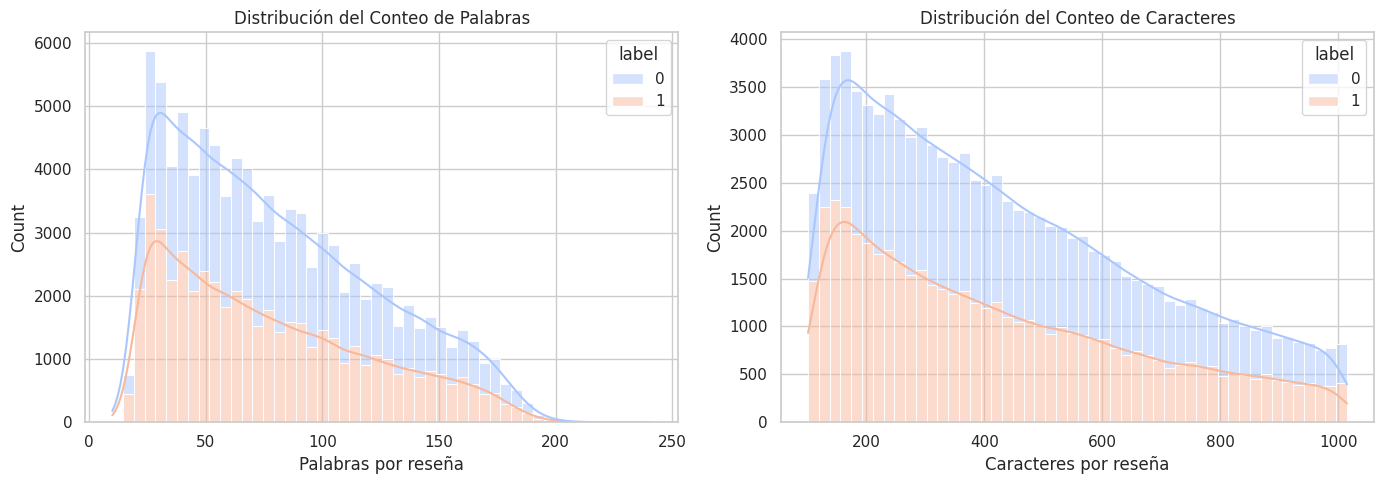

In [7]:
df['char_count'] = df['text'].apply(len)
df['word_count'] = df['text'].apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de palabras
sns.histplot(data=df, x='word_count', hue='label', kde=True, bins=50, ax=axes[0], palette='coolwarm', multiple='stack')
axes[0].set_title('Distribución del Conteo de Palabras')
axes[0].set_xlabel('Palabras por reseña')

# Histograma de caracteres
sns.histplot(data=df, x='char_count', hue='label', kde=True, bins=50, ax=axes[1], palette='coolwarm', multiple='stack')
axes[1].set_title('Distribución del Conteo de Caracteres')
axes[1].set_xlabel('Caracteres por reseña')

plt.tight_layout()
plt.show()

## 5. Frecuencia de Palabras y N-gramas
Extraeremos los términos más comunes utilizando un preprocesamiento rápido para limpiar ruidos de puntuación.

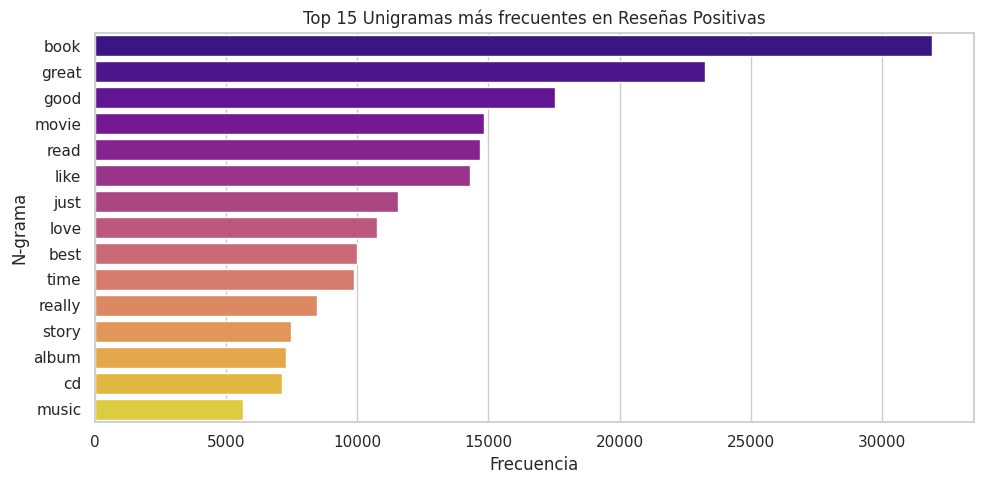

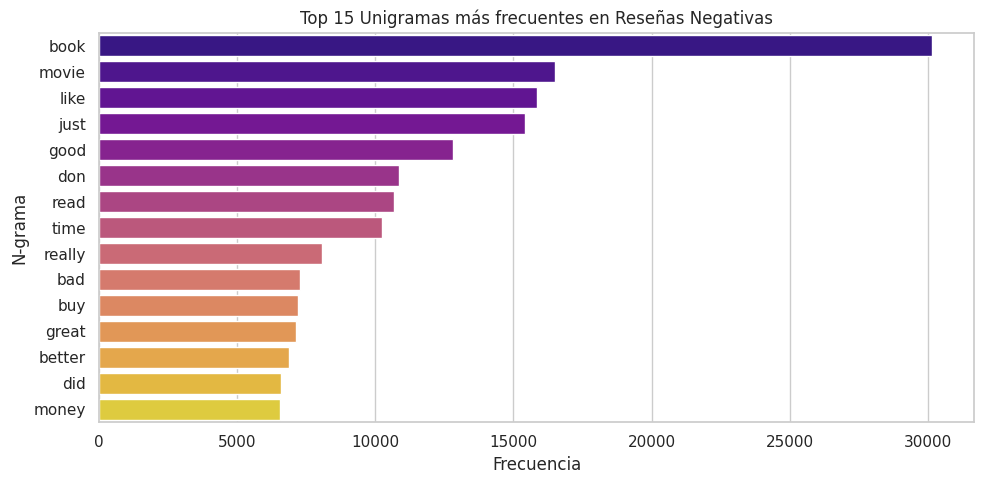

In [8]:
from src.preprocessing import clean_text
from sklearn.feature_extraction.text import CountVectorizer

# Limpiar texto de la muestra
df['cleaned_text'] = df['text'].apply(clean_text)

def plot_top_ngrams(corpus, n=1, title="Top N-gramas", top_k=15):
    vec = CountVectorizer(ngram_range=(n, n), stop_words="english").fit(corpus)
    counts = vec.transform(corpus).sum(axis=0)
    words_freq = sorted(
        [(word, counts[0, idx]) for word, idx in vec.vocabulary_.items()],
        key=lambda x: x[1],
        reverse=True
    )[:top_k]

    ngram_df = pd.DataFrame(words_freq, columns=["ngram", "count"])

    plt.figure(figsize=(10, 5))
    sns.barplot(data=ngram_df, x="count", y="ngram", hue="ngram",
                palette="plasma", legend=False)
    plt.title(title)
    plt.xlabel("Frecuencia")
    plt.ylabel("N-grama")
    plt.tight_layout()
    plt.show()

# Unigramas frecuentes para reseñas Positivas
plot_top_ngrams(df[df['label']==1]['cleaned_text'], n=1, title="Top 15 Unigramas más frecuentes en Reseñas Positivas")

# Unigramas frecuentes para reseñas Negativas
plot_top_ngrams(df[df['label']==0]['cleaned_text'], n=1, title="Top 15 Unigramas más frecuentes en Reseñas Negativas")

## 6. Exportación de Porciones como CSV
Parseamos el formato fastText, extraemos 120k registros de train y 24k de test, y guardamos como CSV en `data/raw/`.

In [9]:
train_file = f'{DOWNLOAD_DIR}/train.ft.txt.bz2'
test_file = f'{DOWNLOAD_DIR}/test.ft.txt.bz2'
df_train = load_subset(train_file, max_records=120000)
df_test = load_subset(test_file, max_records=24000)

shutil.rmtree(DOWNLOAD_DIR)
print("Descarga temporal eliminada. Subsetting completado.")

df_train.to_csv(os.path.join(RAW_DIR, 'train.csv'), index=False)
df_test.to_csv(os.path.join(RAW_DIR, 'test.csv'), index=False)

print("¡Conjuntos procesados guardados con éxito en data/raw/!")

Descarga temporal eliminada. Subsetting completado.
¡Conjuntos procesados guardados con éxito en data/raw/!
